> **Long run.** Same notebook with numbers of replicas, toy experiments and chain lengths close to those of the report.

# 09 · Machine learning (2/2): effect on the measurement and unsupervised partition of the Dalitz plane

**What this notebook does.** The classifier of notebook 08 is *used*: does a cut on its score change $A_{\rm raw}$? The
mass fit is repeated on the selected sample with the three methods (counting, frequentist, Bayesian) and the worsening
of the fit is explained (sculpting or change of the background composition). Then $K$-means partitions the Dalitz plane
*without labels*, and finally a high-background sample shows where an ML selection could really help.

| § | Content | Report section |
|---|---|---|
| 6 | Stability of $A_{\rm raw}$ against the score threshold, refits, sculpting test [EXTRA] | Effect on the measurement |
| 7 | $K$-means on the Dalitz plane, silhouette, stability (adjusted Rand index) | Effect on the measurement (add.: K-means) |
| 8 | High-background sample | Add.: stability of $A_{\rm raw}$ |

**Scale.** A guided tour of the method, not the production run: replicas, toy experiments and chains are fewer than in
the report, so numbers can differ slightly from it; next to every result the notebook prints the value of the report
(**report:**). The notebook is self-contained and saves its figures in `figures/` and its numbers in `results/`.
Parts beyond the techniques of the course are tagged **[EXTRA]**.

## 0 · Setup

In [1]:
import os, time, warnings, copy, json
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from scipy.stats import norm, chi2, spearmanr
from iminuit import Minuit, cost
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, accuracy_score, silhouette_score, adjusted_rand_score
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import KMeans
import tensorflow as tf
from tensorflow import keras

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()
SEED = 42
np.random.seed(SEED)

# figures and numerical results are saved next to the notebook
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save_fig(name):
    """Save the current figure in figures/ and show it."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
M_K = 493.677
LO, HI = 5100.0, 5600.0

## 1 · Data and weak labels

### 1.1 Data
Same preselection and window as in the other notebooks, now with the *features* for the classifiers: for each
of the three tracks the momentum components, the two PID likelihoods and the impact-parameter $\chi^2$ (18 features),
plus two variables of the $B$ candidate (flight distance, vertex $\chi^2$): **20 features, the mass is not one of them**.
We keep a looser PID sample (`ProbK` > 0.3) for the study of §8 and select the nominal one from it.

In [2]:
tracks = (1, 2, 3)                                     # the three final-state hadrons
# the 20 features: for each track momentum components, PID likelihoods and impact-parameter chi2 (18) + 2 of the B
FEATURES = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "IPChi2")] + ["B_FlightDistance", "B_VertexChi2"]
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge", "IPChi2")]
branches += ["B_FlightDistance", "B_VertexChi2"]
frames = []
for pol in ("Down", "Up"):                             # one file per magnet polarity
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        t = f["DecayTree"].arrays(branches, library="pd")
    t["magnet"] = pol.lower()
    frames.append(t)
df = pd.concat(frames, ignore_index=True)
# loose preselection: ProbK > 0.3 (the nominal one is ProbK > 0.5, applied below)
keep = np.ones(len(df), bool)
for i in tracks:
    keep &= ((df[f"H{i}_ProbK"] > 0.3) & (df[f"H{i}_ProbPi"] < 0.5) & ~df[f"H{i}_isMuon"].astype(bool)).to_numpy()
d = df[keep].reset_index(drop=True); del df

def invariant_mass(d, particles):
    """Invariant mass [MeV] of the listed tracks, kaon mass hypothesis."""
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"], d["m12"], d["m13"] = invariant_mass(d, (1, 2, 3)), invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"] = d.H1_Charge + d.H2_Charge + d.H3_Charge                     # charge of the B
d["min_probk"] = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)      # weakest kaon likelihood of the candidate
d = d[(np.abs(d.q) == 1) & (d.m > LO) & (d.m < HI)].reset_index(drop=True)
data = d[d.min_probk > 0.5].reset_index(drop=True)                   # nominal sample (ProbK > 0.5 on all tracks)
print(f"candidates in the window: nominal {len(data)} (report 19731),  looser ProbK > 0.3: {len(d)} (report 33328)")

candidates in the window: nominal 19731 (report 19731),  looser ProbK > 0.3: 33328 (report 33328)


### 1.2 Mass fit: $\mu$ and $\sigma$ for the labels

A compact version of the nominal fit of notebook 01 (simultaneous fit of $B^+$ and $B^-$, Gaussian signal,
double-exponential background per charge). We need it now for $\mu$ and $\sigma$, and in §6 and §8 to refit the
selected samples. Model and fit are written exactly as in notebook 01.

In [3]:
# --- the nominal mass model and fit, exactly as in notebook 01 (here to obtain mu and sigma, and to refit later)
def gauss_pdf(m, mu, sigma):
    """Gaussian normalised on the fit window [LO, HI]."""
    return norm.pdf(m, mu, sigma) / (norm.cdf(HI, mu, sigma) - norm.cdf(LO, mu, sigma))
def exp_pdf(m, lam):
    """Exponential normalised on the window."""
    return lam * np.exp(-lam * (m - LO)) / (1 - np.exp(-lam * (HI - LO)))
def bkg_pdf(m, lam1, lam2, f):
    """Background: two exponentials, weight f on the steep one."""
    return f * exp_pdf(m, lam1) + (1 - f) * exp_pdf(m, lam2)

# one extended model per charge; N_s, A, mu, sigma are shared by the two (same name)
def model_pos(m, N_s, A, mu, sigma, N_b_pos, lam1_pos, lam2_pos, f_pos):
    n_sig = N_s * (1 - A) / 2                                          # B+ : (1 - A) / 2
    return n_sig + N_b_pos, n_sig * gauss_pdf(m, mu, sigma) + N_b_pos * bkg_pdf(m, lam1_pos, lam2_pos, f_pos)
def model_neg(m, N_s, A, mu, sigma, N_b_neg, lam1_neg, lam2_neg, f_neg):
    n_sig = N_s * (1 + A) / 2                                          # B- : (1 + A) / 2
    return n_sig + N_b_neg, n_sig * gauss_pdf(m, mu, sigma) + N_b_neg * bkg_pdf(m, lam1_neg, lam2_neg, f_neg)

def fit_asymmetry(s):
    """Nominal simultaneous fit on a sample s (columns m, q). Returns the Minuit object (A, errors, chi2 via fval)."""
    mp, mn = s.m[s.q > 0].to_numpy(), s.m[s.q < 0].to_numpy()
    nll = cost.ExtendedUnbinnedNLL(mp, model_pos) + cost.ExtendedUnbinnedNLL(mn, model_neg)     # sum of the two charges
    f = Minuit(nll, N_s=0.78 * len(s), A=-0.04, mu=5284.0, sigma=18.0,
               N_b_pos=0.22 * len(mp), lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15,
               N_b_neg=0.22 * len(mn), lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)
    f.limits["A"] = (-1, 1); f.limits["mu"] = (5260, 5310); f.limits["sigma"] = (3, 40)
    f.limits["N_s"] = (0, 2 * len(s))
    for side in ("pos", "neg"):
        f.limits[f"N_b_{side}"] = (0, 2 * len(s))
        f.limits[f"lam1_{side}"] = (1e-5, 0.1); f.limits[f"lam2_{side}"] = (1e-5, 0.1); f.limits[f"f_{side}"] = (0, 1)
    f.migrad(); f.hesse()
    return f

fit_all = fit_asymmetry(data)
MU, SIGMA = fit_all.values["mu"], fit_all.values["sigma"]              # peak position and resolution
A_full, dA_full = fit_all.values["A"], fit_all.errors["A"]             # result on the full sample, for comparison
print(f"mu = {MU:.2f} MeV, sigma = {SIGMA:.2f} MeV;  A_raw = {A_full:+.4f} +- {dA_full:.4f}   (report: 5284.39, 18.00, -0.0441 +- 0.0085)")

mu = 5284.38 MeV, sigma = 18.00 MeV;  A_raw = -0.0441 +- 0.0085   (report: 5284.39, 18.00, -0.0441 +- 0.0085)


### 1.3 Weak labels

No candidate carries a true label. We build **weak labels** from the mass spectrum, following the
*classification without labels* idea (CWoLa): a classifier that separates two samples with *different signal
fractions* — here the window under the peak (mostly signal) and the far sidebands (mostly background) — is, by the
Neyman–Pearson lemma, also the optimal signal/background classifier, **provided the features carry no information on
the mass**. This is why the mass is not a feature.

* signal-like: $|m-\mu|<2\sigma$; background-like: $m\in[5150,\mu-4\sigma]\cup[\mu+4\sigma,5600]$ MeV;
* the gaps $2$–$4\sigma$ and the region below 5150 MeV (partially reconstructed decays, not representative of the
  background under the peak) stay unlabelled.

signal-like 15132, background-like 1939   (report: 15130 and 1940; ratio 0.128)


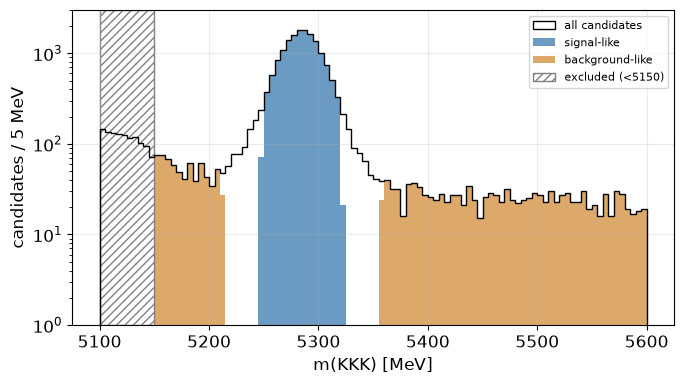

In [4]:
m = data.m.to_numpy()
is_sig = np.abs(m - MU) < 2 * SIGMA                                    # signal-like: within 2 sigma of the peak
# background-like: far sidebands (beyond 4 sigma), above 5150 MeV (below, partially reconstructed decays)
is_bkg = ((m >= 5150) & (m < MU - 4 * SIGMA)) | ((m > MU + 4 * SIGMA) & (m <= HI))
labeled = data[is_sig | is_bkg].copy()                                 # the 2-4 sigma gap stays unlabelled
labeled["y"] = is_sig[is_sig | is_bkg].astype(int)                     # weak label: 1 = signal-like, 0 = background-like
print(f"signal-like {int(labeled.y.sum())}, background-like {int((labeled.y == 0).sum())}   (report: 15130 and 1940; ratio 0.128)")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(LO, HI + 1, 5)
ax.hist(m, bins, histtype="step", color="k", label="all candidates")
ax.hist(m[is_sig], bins, color=C["signal"], alpha=0.8, label="signal-like")
ax.hist(m[is_bkg], bins, color="#d9a05b", alpha=0.9, label="background-like")
ax.axvspan(LO, 5150, facecolor="none", hatch="////", edgecolor="0.5", label="excluded (<5150)")
ax.set(yscale="log", xlabel="m(KKK) [MeV]", ylabel="candidates / 5 MeV", ylim=(1, 3e3)); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("09_weak_labels")

**Train / validation / test split** (stratified 60/20/20) with the standardisation fitted on the training set only.
The classes are imbalanced (0.128): every model uses `balanced` class weights $w_c=N/(2N_c)$.

In [5]:
X, y = labeled[FEATURES].to_numpy(), labeled.y.to_numpy()               # features (the mass is NOT among them) and labels
# stratified split: the class proportions are the same in training, validation and test
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)
scaler = StandardScaler().fit(X_train)                                  # standardisation from the training set only
Xs_train, Xs_val, Xs_test = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)
w = {c: len(y_train) / (2 * np.sum(y_train == c)) for c in (0, 1)}      # balanced class weights w_c = N / (2 N_c)
sw_train = np.where(y_train == 1, w[1], w[0])                           # the same as a weight per training sample
print(f"train/val/test = {len(y_train)}/{len(y_val)}/{len(y_test)};  class weights: {w[0]:.2f} (background), {w[1]:.2f} (signal)")

train/val/test = 10242/3414/3415;  class weights: 4.40 (background), 0.56 (signal)


In [6]:
# the weak labels and the split, saved
pd.DataFrame({"n_window": [len(data)], "n_signal_like": [int(labeled.y.sum())], "n_background_like": [int((labeled.y == 0).sum())],
              "n_train": [len(y_train)], "n_val": [len(y_val)], "n_test": [len(y_test)], "mu": [MU], "sigma": [SIGMA]}).to_csv(
    "results/08_labels_and_split.csv", index=False)

In [7]:
# reference classifier: gradient boosting with balanced sample weights (as in notebook 08, section 3)
gbm = GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=SEED)
gbm.fit(X_train, y_train, sample_weight=sw_train)
print(f"test AUC of the reference classifier: {roc_auc_score(y_test, gbm.predict_proba(X_test)[:, 1]):.4f}")

test AUC of the reference classifier: 0.8703


## 6 · Use in the measurement: does the ML selection change $A_{\rm raw}$?

The reference classifier (gradient boosting, best cross-validated AUC) scores **all** candidates of the window. A cut on
the score defines a sub-sample; every sub-sample is contained in the full one. The expected statistical fluctuation of
the difference between two *nested* estimates is **not** the quadrature sum of the errors but
$\sqrt{\sigma^2_{\rm sub}-\sigma^2_{\rm full}}$.

threshold      N  eff(signal-like)   A_count   sigma  expected spread    shift
      0.1  18315              0.99   -0.0457  0.0074           0.0020  -0.0025
      0.3  17115              0.95   -0.0461  0.0076           0.0028  -0.0029
      0.5  15865              0.90   -0.0466  0.0079           0.0035  -0.0033
      0.7  13136              0.76   -0.0452  0.0087           0.0050  -0.0020
      0.9   4348              0.26   -0.0391  0.0152           0.0134  +0.0041


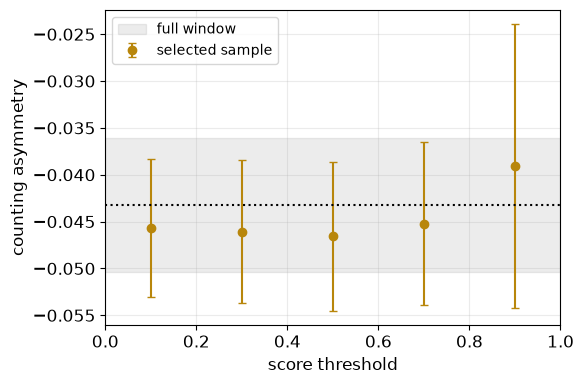

In [8]:
score_all = gbm.predict_proba(data[FEATURES].to_numpy())[:, 1]       # score of EVERY candidate of the window
data["score"] = score_all

def count_asym(q):
    """Counting asymmetry A = (N- - N+)/N and its binomial uncertainty."""
    n = len(q); a = (np.sum(q < 0) - np.sum(q > 0)) / n
    return a, np.sqrt((1 - a**2) / n)

a_full, da_full = count_asym(data.q.to_numpy())                      # counting asymmetry of the full window
print(f"{'threshold':>9s} {'N':>6s} {'eff(signal-like)':>17s} {'A_count':>9s} {'sigma':>7s} {'expected spread':>16s} {'shift':>8s}")
thr_rows = []
for thr in (0.1, 0.3, 0.5, 0.7, 0.9):
    s = data[data.score > thr]                                       # sample selected by the cut (nested in the full one)
    a, da = count_asym(s.q.to_numpy())
    kept = (data.score > thr).to_numpy()
    spread = np.sqrt(max(da**2 - da_full**2, 0))        # for nested samples sqrt(sigma_sub^2 - sigma_full^2), not the quadrature sum
    thr_rows.append(dict(threshold=thr, n=len(s), efficiency_signal_like=np.mean(kept[is_sig]), A_count=a, sigma=da, expected_spread=spread, shift=a - a_full))
    print(f"{thr:9.1f} {len(s):6d} {np.mean(kept[is_sig]):17.2f} {a:+9.4f} {da:7.4f} {spread:16.4f} {a - a_full:+8.4f}")
thr_tab = pd.DataFrame(thr_rows)
thr_tab.to_csv("results/09_threshold_scan.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(thr_tab.threshold, thr_tab.A_count, thr_tab.sigma, fmt="o", color=C["ml"], capsize=3, label="selected sample")
ax.axhline(a_full, color="k", ls=":"); ax.fill_between([0, 1], a_full - da_full, a_full + da_full, color="gray", alpha=0.15, label="full window")
ax.set(xlabel="score threshold", ylabel="counting asymmetry", xlim=(0, 1)); ax.legend()
plt.tight_layout(); save_fig("09_threshold_scan")

**Fit of the selected sample.** At the cut 0.5 we refit the nominal mass model (notebook 01) on the selected
candidates and compare with the full sample. The report finds the asymmetry *stable* (within the nested-sample
spread) and the precision *not improved*, because the nominal sample has little background to remove.

In [9]:
sel = data[data.score > 0.5]                         # the selected sample: score above 0.5
fit_sel = fit_asymmetry(sel)                         # nominal mass fit (as in notebook 01) on the selected candidates
exp_spread = np.sqrt(abs(fit_sel.errors["A"]**2 - dA_full**2))       # expected shift between nested samples
print(f"kept {len(sel)} candidates ({100 * len(sel) / len(data):.0f}%)    (report: 15709)")
print(f"full sample:     A = {A_full:+.4f} +- {dA_full:.4f}")
print(f"selected sample: A = {fit_sel.values['A']:+.4f} +- {fit_sel.errors['A']:.4f}   shift {fit_sel.values['A'] - A_full:+.4f} "
      f"(expected spread {exp_spread:.4f})   (report: -0.0447 +- 0.0086)")
print(f"significance of A=0 in the selected sample: ~ {abs(fit_sel.values['A']) / fit_sel.errors['A']:.1f} sigma   (report: 5.2)")

kept 15865 candidates (80%)    (report: 15709)
full sample:     A = -0.0441 +- 0.0085
selected sample: A = -0.0454 +- 0.0085   shift -0.0013 (expected spread 0.0007)   (report: -0.0447 +- 0.0086)
significance of A=0 in the selected sample: ~ 5.3 sigma   (report: 5.2)


**Reading the result.** The selected sample gives an asymmetry compatible with the full one within the spread expected between nested samples, and with practically the same uncertainty: the selection does not improve the precision because the nominal sample has little background to remove.

**The same question with a Bayesian fit.** Same likelihood and uniform priors as in notebook 05, sampled with
`emcee` on the selected candidates. With the counting asymmetry and the frequentist fit above this gives three
estimates of the shift of $A_{\rm raw}$ caused by the selection.

In [10]:
import emcee
bnames = ["N_s", "N_b", "A", "A_b", "mu", "sigma", "lam1_pos", "lam2_pos", "f_pos", "lam1_neg", "lam2_neg", "f_neg"]

def log_posterior(theta, m_p, m_n, n_cand):
    """ln posterior (uniform priors) of the nominal model, as in notebook 05."""
    v = dict(zip(bnames, theta))
    # prior: allowed range of each parameter (zero outside)
    box = {"N_s": (0, 5 * n_cand), "N_b": (0, 5 * n_cand), "A": (-1, 1), "A_b": (-1, 1), "mu": (5260, 5310), "sigma": (3, 40)}
    for k in bnames:
        lo_k, hi_k = box.get(k, (0, 1) if k.startswith("f_") else (1e-5, 0.1))
        if not lo_k < v[k] < hi_k:
            return -np.inf
    if v["lam1_pos"] <= v["lam2_pos"] or v["lam1_neg"] <= v["lam2_neg"]:      # ordering of the two exponentials
        return -np.inf
    # extended unbinned likelihood: signal + background for each charge
    dens = []
    for side, sign, mm in (("pos", -1, m_p), ("neg", +1, m_n)):
        n_s = v["N_s"] * (1 + sign * v["A"]) / 2
        n_b = v["N_b"] * (1 + sign * v["A_b"]) / 2
        dens.append(n_s * gauss_pdf(mm, v["mu"], v["sigma"]) + n_b * bkg_pdf(mm, v[f"lam1_{side}"], v[f"lam2_{side}"], v[f"f_{side}"]))
    return np.sum(np.log(dens[0])) + np.sum(np.log(dens[1])) - (v["N_s"] + v["N_b"])

mp_sel, mn_sel = sel.m[sel.q > 0].to_numpy(), sel.m[sel.q < 0].to_numpy()
fv = fit_sel.values
# start the walkers around the maximum-likelihood fit of the selected sample
x0 = np.array([fv["N_s"], fv["N_b_pos"] + fv["N_b_neg"], fv["A"], (fv["N_b_neg"] - fv["N_b_pos"]) / (fv["N_b_pos"] + fv["N_b_neg"]),
               fv["mu"], fv["sigma"], fv["lam1_pos"], fv["lam2_pos"], fv["f_pos"], fv["lam1_neg"], fv["lam2_neg"], fv["f_neg"]])
p0 = x0 + 1e-3 * np.abs(x0) * np.random.randn(32, len(x0))
p0[:, 2] = x0[2] + 1e-3 * np.random.randn(32); p0[:, 3] = x0[3] + 1e-3 * np.random.randn(32)     # A, A_b: absolute spread
sam = emcee.EnsembleSampler(32, len(x0), log_posterior, args=(mp_sel, mn_sel, len(sel)))
sam.run_mcmc(p0, 25000, progress=False)
A_bayes_sel = sam.get_chain(discard=5000, flat=True)[:, 2]            # posterior of A: third parameter
a_cnt_sel, da_cnt_sel = count_asym(sel.q.to_numpy())
print(f"selected sample, three methods:  counting {a_cnt_sel:+.4f} +- {da_cnt_sel:.4f}   frequentist {fit_sel.values['A']:+.4f} +- "
      f"{fit_sel.errors['A']:.4f}   Bayesian {np.median(A_bayes_sel):+.4f} +- {A_bayes_sel.std():.4f}")
print("report (selected sample): Bayesian -0.0451 +- 0.0087, frequentist -0.0447 +- 0.0086; full sample -0.0443 and -0.0441")

selected sample, three methods:  counting -0.0466 +- 0.0079   frequentist -0.0454 +- 0.0085   Bayesian -0.0455 +- 0.0085
report (selected sample): Bayesian -0.0451 +- 0.0087, frequentist -0.0447 +- 0.0086; full sample -0.0443 and -0.0441


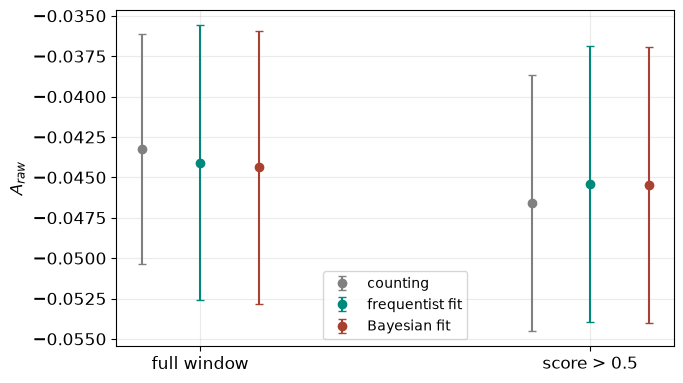

In [11]:
# the three estimates for the full and the selected sample (Bayesian full sample: a second chain on the full window)
mp_all, mn_all = data.m[data.q > 0].to_numpy(), data.m[data.q < 0].to_numpy()
fa = fit_all.values
x0a = np.array([fa["N_s"], fa["N_b_pos"] + fa["N_b_neg"], fa["A"], (fa["N_b_neg"] - fa["N_b_pos"]) / (fa["N_b_pos"] + fa["N_b_neg"]),
                fa["mu"], fa["sigma"], fa["lam1_pos"], fa["lam2_pos"], fa["f_pos"], fa["lam1_neg"], fa["lam2_neg"], fa["f_neg"]])
p0a = x0a + 1e-3 * np.abs(x0a) * np.random.randn(32, len(x0a))
p0a[:, 2] = x0a[2] + 1e-3 * np.random.randn(32); p0a[:, 3] = x0a[3] + 1e-3 * np.random.randn(32)
sam_a = emcee.EnsembleSampler(32, len(x0a), log_posterior, args=(mp_all, mn_all, len(data)))
sam_a.run_mcmc(p0a, 25000, progress=False)
A_bayes_full = sam_a.get_chain(discard=5000, flat=True)[:, 2]
a_cnt_full, da_cnt_full = count_asym(data.q.to_numpy())
three = pd.DataFrame([
    dict(sample="full", method="counting", A=a_cnt_full, err=da_cnt_full),
    dict(sample="full", method="frequentist fit", A=A_full, err=dA_full),
    dict(sample="full", method="Bayesian fit", A=np.median(A_bayes_full), err=A_bayes_full.std()),
    dict(sample="score > 0.5", method="counting", A=a_cnt_sel, err=da_cnt_sel),
    dict(sample="score > 0.5", method="frequentist fit", A=fit_sel.values["A"], err=fit_sel.errors["A"]),
    dict(sample="score > 0.5", method="Bayesian fit", A=np.median(A_bayes_sel), err=A_bayes_sel.std())])
three.to_csv("results/09_three_methods.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
for k_, (meth, col_) in enumerate((("counting", "gray"), ("frequentist fit", C["freq"]), ("Bayesian fit", C["bayes"]))):
    for j_, smp in enumerate(("full", "score > 0.5")):
        r = three[(three.method == meth) & (three["sample"] == smp)].iloc[0]
        ax.errorbar(j_ + 0.15 * (k_ - 1), r.A, r.err, fmt="o", color=col_, capsize=3, label=meth if j_ == 0 else None)
ax.set(xticks=[0, 1], xticklabels=["full window", "score > 0.5"], ylabel="$A_{raw}$"); ax.legend()
plt.tight_layout(); save_fig("09_three_methods")

**Why does the mass spectrum change after the cut? Sculpting test** [EXTRA]. The fit of the selected sample is
*worse*. Two hypotheses: (a) the classifier reconstructs the mass from the kaon momenta and removes events
preferentially in the sidebands (*sculpting*); (b) the selection changes the *composition* of the background,
keeping partially reconstructed decays that the model does not describe. Test: retrain without the nine momentum
components (the only features with information on the mass). If (a) were true the degradation would disappear.

In [12]:
def binned_chi2(f, s, width=10.0):
    """Pearson chi2 in bins of 10 MeV, both charges, of the fit f (Minuit) on the sample s."""
    edges = np.arange(LO, HI + 1e-9, width)
    pts = edges[:-1, None] + ((np.arange(5) + 0.5) / 5)[None, :] * width      # 5 points per bin to average the density
    v = f.values
    nu_p = model_pos(pts, *[v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_pos", "lam1_pos", "lam2_pos", "f_pos")])[1].mean(axis=1) * width
    nu_n = model_neg(pts, *[v[k] for k in ("N_s", "A", "mu", "sigma", "N_b_neg", "lam1_neg", "lam2_neg", "f_neg")])[1].mean(axis=1) * width
    op, on = np.histogram(s.m[s.q > 0], edges)[0], np.histogram(s.m[s.q < 0], edges)[0]      # observed counts
    return np.sum((op - nu_p)**2 / nu_p) + np.sum((on - nu_n)**2 / nu_n)

# retrain the classifier WITHOUT the momentum components: it then has no information on the mass
no_mom = [i for i, f_ in enumerate(FEATURES) if not f_.endswith(("_PX", "_PY", "_PZ"))]
gbm_nomom = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED)
gbm_nomom.fit(X_train[:, no_mom], y_train, sample_weight=sw_train)
sel_nomom = data[gbm_nomom.predict_proba(data[FEATURES].to_numpy()[:, no_mom])[:, 1] > 0.5]
fit_nomom = fit_asymmetry(sel_nomom)
print(f"chi2/ndof (10 MeV bins, ndof = 88):  full {binned_chi2(fit_all, data):.0f},  selected {binned_chi2(fit_sel, sel):.0f},  "
      f"selected without momenta {binned_chi2(fit_nomom, sel_nomom):.0f}")
print("report: full 164 -> selected 253 (Bayesian fit); without momenta the degradation is the same -> not sculpting, "
      "a change in the background composition")

chi2/ndof (10 MeV bins, ndof = 88):  full 160,  selected 257,  selected without momenta 229
report: full 164 -> selected 253 (Bayesian fit); without momenta the degradation is the same -> not sculpting, a change in the background composition


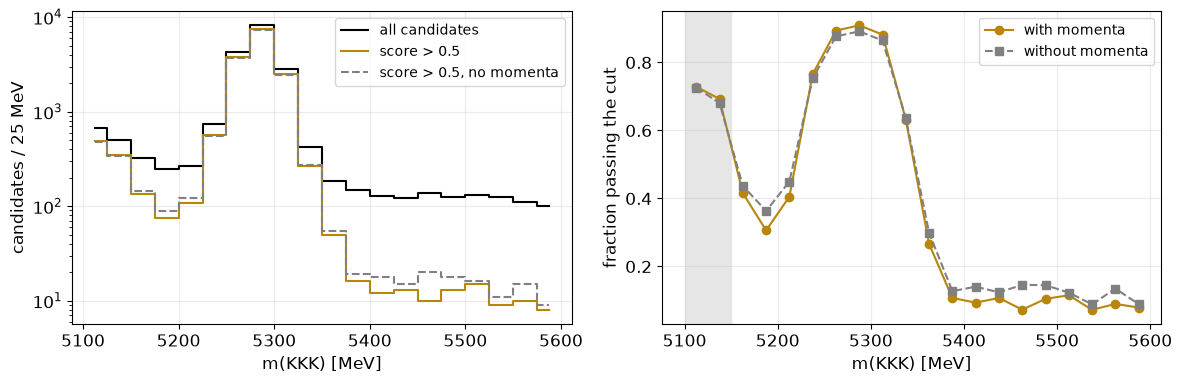

In [13]:
# mass spectra before and after the cut (with and without the momentum features) and efficiency against the mass
bins_c = np.arange(LO, HI + 1, 25)
cen_c = 0.5 * (bins_c[1:] + bins_c[:-1])
n_all, n_sel, n_nm = np.histogram(data.m, bins_c)[0], np.histogram(sel.m, bins_c)[0], np.histogram(sel_nomom.m, bins_c)[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].step(cen_c, n_all, where="mid", color="k", label="all candidates")
ax[0].step(cen_c, n_sel, where="mid", color=C["ml"], label="score > 0.5")
ax[0].step(cen_c, n_nm, where="mid", color="gray", ls="--", label="score > 0.5, no momenta")
ax[0].set(yscale="log", xlabel="m(KKK) [MeV]", ylabel="candidates / 25 MeV"); ax[0].legend()
ax[1].plot(cen_c, n_sel / n_all, "o-", color=C["ml"], label="with momenta"); ax[1].plot(cen_c, n_nm / n_all, "s--", color="gray", label="without momenta")
ax[1].axvspan(LO, 5150, color="0.9"); ax[1].set(xlabel="m(KKK) [MeV]", ylabel="fraction passing the cut"); ax[1].legend()
plt.tight_layout(); save_fig("09_mass_after_cut")
pd.DataFrame({"m_center": cen_c, "all": n_all, "selected": n_sel, "selected_no_momenta": n_nm}).to_csv("results/09_mass_after_cut.csv", index=False)

## 7 · $K$-means on the Dalitz plane

In notebook 04 the Dalitz plane was divided with a **fixed** $8\times8$ grid. Here the partition is **learned from the
data** without labels: $K$-means with $K=8$ (chosen in advance, to be comparable with the grid) on the two
standardised variables $(m^2_{\rm lo},m^2_{\rm hi})$ of all candidates in the window. The asymmetry of each cluster
is compared with the global one as before, $S_k=(A_k-A_{\rm glob})/\sigma(A_k)$, and the homogeneity statistic is
$\chi^2=\sum_kS_k^2$ with $K-1$ degrees of freedom.

In [14]:
# squared masses (GeV^2) of the two opposite-sign pairs, sorted; standardised before K-means (distance-based)
lo2 = (np.minimum(data.m12, data.m13) / 1e3)**2
hi2 = (np.maximum(data.m12, data.m13) / 1e3)**2
Z = StandardScaler().fit_transform(np.column_stack([lo2, hi2]))
km = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit(Z)       # K = 8 fixed in advance, 10 initialisations
qv = data.q.to_numpy()
a_glob = (np.sum(qv < 0) - np.sum(qv > 0)) / len(qv)                 # global counting asymmetry
rows = []
for k in range(8):
    qk = qv[km.labels_ == k]                                         # charges of the candidates of cluster k
    ak, sk = count_asym(qk)
    rows.append((k, len(qk), lo2[km.labels_ == k].mean(), hi2[km.labels_ == k].mean(), ak, sk, (ak - a_glob) / sk))
cl = pd.DataFrame(rows, columns=["cluster", "n", "<m2_lo>", "<m2_hi>", "A", "sigma", "S"])   # S: significance vs global
print(cl.round(3).to_string(index=False))
chi2_k = np.sum(cl.S**2)                                             # homogeneity statistic, K - 1 = 7 d.o.f.
print(f"\nhomogeneity: chi2 = {chi2_k:.1f} for 7 d.o.f., p = {chi2.sf(chi2_k, 7):.1e};  clusters beyond 3 sigma: {np.sum(np.abs(cl.S) > 3)}"
      "     (report: 46.4/7, two clusters beyond 3 sigma)")

 cluster    n  <m2_lo>  <m2_hi>      A  sigma      S
       0 2920    3.200    6.289 -0.044  0.018 -0.033
       1 1953    4.048   11.847 -0.057  0.023 -0.602
       2 4335    1.663   15.749 -0.038  0.015  0.341
       3 1406   10.375   13.665 -0.048  0.027 -0.193
       4 1727    6.597    9.457 -0.014  0.024  1.195
       5 1233    6.206   16.957  0.040  0.028  2.916
       6 3601    1.626   10.752 -0.127  0.017 -5.062
       7 2556    2.450   20.161  0.020  0.020  3.215

homogeneity: chi2 = 46.4 for 7 d.o.f., p = 7.3e-08;  clusters beyond 3 sigma: 2     (report: 46.4/7, two clusters beyond 3 sigma)


**Reading the result.** The partition is learned from the density of the candidates, not from the asymmetry, yet it finds clusters with a significant negative asymmetry at low $m^2_{\rm lo}$ and positive ones at high $m^2_{\rm hi}$: the same pattern as the fixed grid. The homogeneity $\chi^2$ is far above its 7 degrees of freedom.

**How to choose $K$** (course): inertia (sum of squared distances to the centroids) always decreases with $K$ — look
for an elbow; the *silhouette* [EXTRA] measures how well separated the clusters are. $K=8$ was *fixed in advance* and
is not the silhouette optimum. **Stability** [EXTRA]: the adjusted Rand index between two initialisations tells
whether the partition is reproducible.

adjusted Rand index between two seeds (K = 8): 0.976   (report: > 0.998)
silhouette maximum at K = 3   (report: K = 3)


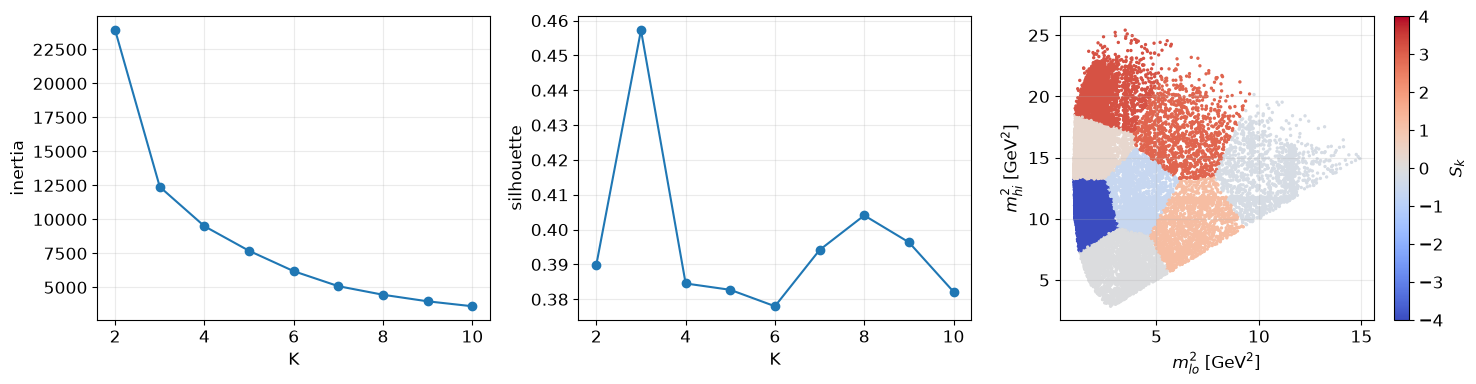

In [15]:
Ks = range(2, 11)
inertia, sil = [], []
sub = np.random.choice(len(Z), 4000, replace=False)                  # silhouette on a subsample (it is O(N^2))
for K in Ks:
    kmk = KMeans(n_clusters=K, n_init=5, random_state=SEED).fit(Z)
    inertia.append(kmk.inertia_)                                     # sum of squared distances to the centroids
    sil.append(silhouette_score(Z[sub], kmk.labels_[sub]))           # how well separated the clusters are
# stability: two different initialisations should give the same partition (adjusted Rand index ~ 1)
km2 = KMeans(n_clusters=8, n_init=10, random_state=7).fit(Z)
print(f"adjusted Rand index between two seeds (K = 8): {adjusted_rand_score(km.labels_, km2.labels_):.3f}   (report: > 0.998)")
print(f"silhouette maximum at K = {list(Ks)[int(np.argmax(sil))]}   (report: K = 3)")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(list(Ks), inertia, "o-"); ax[0].set(xlabel="K", ylabel="inertia")
ax[1].plot(list(Ks), sil, "o-"); ax[1].set(xlabel="K", ylabel="silhouette")
# the K = 8 partition, each candidate coloured by the significance of its cluster
sc_ = ax[2].scatter(lo2, hi2, c=cl.S.values[km.labels_], s=2, cmap="coolwarm", vmin=-4, vmax=4)
plt.colorbar(sc_, ax=ax[2], label="$S_k$"); ax[2].set(xlabel="$m^2_{lo}$ [GeV$^2$]", ylabel="$m^2_{hi}$ [GeV$^2$]")
plt.tight_layout(); save_fig("09_kmeans")
cl.to_csv("results/09_kmeans_clusters.csv", index=False)
pd.DataFrame({"K": list(Ks), "inertia": inertia, "silhouette": sil}).to_csv("results/09_kmeans_inertia_silhouette.csv", index=False)
np.save("results/09_kmeans_labels.npy", km.labels_)

## 8 · A high-background sample: where an ML selection could really help

In the nominal sample the background under the peak is small and the ML selection does not improve $\sigma(A)$.
Starting from a *looser* PID selection ($\texttt{ProbK}>0.3$, much more background) we compare two ways of cleaning it
**at equal signal efficiency**: tightening the PID cut ($\texttt{ProbK}>0.4,\dots,0.8$) or cutting on the score of the
classifier retrained on the weak labels of this sample (same features and hyperparameters).
Signal efficiency is $N_s$ of the fit relative to $N_s$ of the loose sample.

loose sample: 33328 candidates, A = -0.0552 +- 0.0072, N_s = 22593


selection    cut  signal_eff       A  sigma_A
  PID cut 0.4000      0.8594 -0.0473   0.0076
  PID cut 0.5000      0.6785 -0.0441   0.0085
  PID cut 0.6000      0.4975 -0.0383   0.0098
  PID cut 0.7000      0.3165 -0.0553   0.0123
  PID cut 0.8000      0.1781 -0.0431   0.0163
score cut 0.3000      0.9804 -0.0560   0.0070
score cut 0.5000      0.9253 -0.0552   0.0071
score cut 0.7000      0.7741 -0.0541   0.0077
score cut 0.8000      0.5882 -0.0464   0.0088
score cut 0.9000      0.2097 -0.0536   0.0147


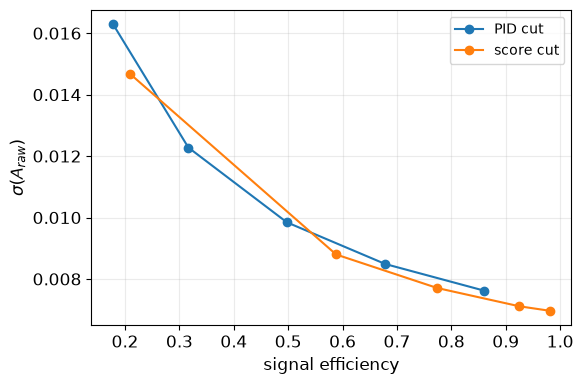

signal efficiency 0.98:  sigma(A) score cut 0.0070   PID cut 0.0076
signal efficiency 0.93:  sigma(A) score cut 0.0071   PID cut 0.0076
signal efficiency 0.77:  sigma(A) score cut 0.0077   PID cut 0.0080
signal efficiency 0.59:  sigma(A) score cut 0.0088   PID cut 0.0092
signal efficiency 0.21:  sigma(A) score cut 0.0147   PID cut 0.0154
In the nominal sample (ProbK > 0.5) the background is small; here, with much more background, the score cut gives a
somewhat smaller sigma(A) than the PID cut at equal signal efficiency (this study is among the additional results of the report).


In [16]:
loose = d.copy()                                              # looser PID: ProbK > 0.3, much more background
fit_loose = fit_asymmetry(loose)
Ns_ref = fit_loose.values["N_s"]                              # signal yield of the loose sample = 100 % efficiency
print(f"loose sample: {len(loose)} candidates, A = {fit_loose.values['A']:+.4f} +- {fit_loose.errors['A']:.4f}, N_s = {Ns_ref:.0f}")

# weak labels of the loose sample and a classifier retrained on them (same features and hyperparameters)
ml = loose.m.to_numpy()
sig_l = np.abs(ml - MU) < 2 * SIGMA
bkg_l = ((ml >= 5150) & (ml < MU - 4 * SIGMA)) | ((ml > MU + 4 * SIGMA) & (ml <= HI))
lab_l = loose[sig_l | bkg_l]
y_l = sig_l[sig_l | bkg_l].astype(int)
sw_l = np.where(y_l == 1, len(y_l) / (2 * y_l.sum()), len(y_l) / (2 * (len(y_l) - y_l.sum())))    # balanced weights
gbm_l = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED)
gbm_l.fit(lab_l[FEATURES].to_numpy(), y_l, sample_weight=sw_l)
loose = loose.assign(score=gbm_l.predict_proba(loose[FEATURES].to_numpy())[:, 1])

# two ways of cleaning the sample: tighter PID cut, or cut on the classifier score; efficiency = N_s / N_s(loose)
rows = []
for k in (0.4, 0.5, 0.6, 0.7, 0.8):
    f = fit_asymmetry(loose[loose.min_probk > k])
    rows.append(("PID cut", k, f.values["N_s"] / Ns_ref, f.values["A"], f.errors["A"]))
for t in (0.3, 0.5, 0.7, 0.8, 0.9):
    f = fit_asymmetry(loose[loose.score > t])
    rows.append(("score cut", t, f.values["N_s"] / Ns_ref, f.values["A"], f.errors["A"]))
hb = pd.DataFrame(rows, columns=["selection", "cut", "signal_eff", "A", "sigma_A"])
print(hb.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
fig, ax = plt.subplots(figsize=(6, 4))
for sel_name, g in hb.groupby("selection"):
    ax.plot(g.signal_eff, g.sigma_A, "o-", label=sel_name)
ax.set(xlabel="signal efficiency", ylabel="$\\sigma(A_{raw})$"); ax.legend(); plt.tight_layout(); save_fig("09_high_background")
# sigma(A) of the PID cut interpolated at the signal efficiency of each score cut: compare at EQUAL efficiency
pid, ml_ = hb[hb.selection == "PID cut"].sort_values("signal_eff"), hb[hb.selection == "score cut"]
sig_pid = np.interp(ml_.signal_eff, pid.signal_eff, pid.sigma_A)
for e, s_ml, s_pid in zip(ml_.signal_eff, ml_.sigma_A, sig_pid):
    print(f"signal efficiency {e:.2f}:  sigma(A) score cut {s_ml:.4f}   PID cut {s_pid:.4f}")
print("In the nominal sample (ProbK > 0.5) the background is small; here, with much more background, the score cut gives a")
print("somewhat smaller sigma(A) than the PID cut at equal signal efficiency (this study is among the additional results of the report).")

## Results saved

In [17]:
summary = dict(
    selection=dict(threshold=0.5, n_kept=int(len(sel)), A_full=float(A_full), A_selected=float(fit_sel.values["A"]),
                   err_selected=float(fit_sel.errors["A"]), A_bayes_selected=float(np.median(A_bayes_sel)),
                   A_counting_selected=float(a_cnt_sel)),
    kmeans=dict(K=8, chi2=float(chi2_k), ndof=7))
json.dump(summary, open("results/09_summary.json", "w"), indent=1)
cl.to_csv("results/09_kmeans_clusters.csv", index=False); hb.to_csv("results/09_high_background.csv", index=False)
print("saved results/09_summary.json and the tables; figures in figures/")

saved results/09_summary.json and the tables; figures in figures/


## Summary
* A cut on the score leaves $A_{\rm raw}$ **unchanged** within the statistical spread expected between nested samples,
  with the three methods, and does not improve the precision (little background to remove).
* The mass spectrum changes after the cut: the classifier does **not sculpt** the mass (the degradation is the same
  without the momenta); the selection changes the composition of the background.
* $K$-means on the Dalitz plane finds the same local pattern as the fixed grid of notebook 04.
* In a high-background sample the score cut is slightly more efficient than tightening the PID requirement.

In [18]:
print(f"Running time of this notebook: {(time.time() - T0) / 60:.1f} min")

Running time of this notebook: 14.4 min
